Simulate 4 × 105 possessions with random outcomes, η = 0.02, a running-average baseline, from θ = (0.3, −0.3). Add an entropy bonus by putting −τθ p(1 − p) inside the bracket that multiplies η, and run τ = 0 and 0.05. (i) Plot the mean-flow orbit of (b) from (0.2, 0.3); report the range of x, y and the variation of K. (ii) Plot (x, y) for both runs; report the last-quarter average and mean distance from (x ∗, y∗) early and late. (iii) Why does the τ = 0 learner drift outward, and what does the bonus change?

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad

# Parameters
eta = 0.02
N = 400000
x_star = 8/17
y_star = 9/17

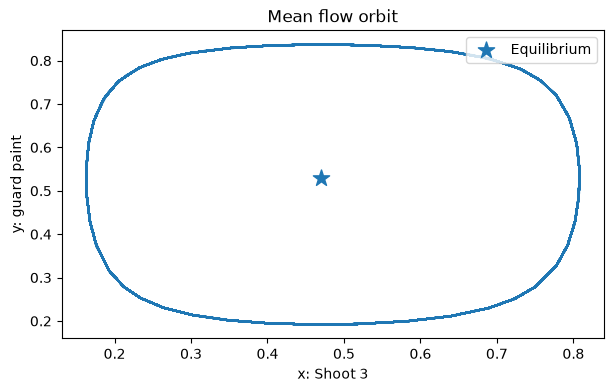

x range: 0.16300961033958333 0.807958581417626
y range: 0.19193026250577871 0.8372135040734227
K variation: 1.8783656852150443e-09


In [8]:
# Part (i) 
def mean_flow(t, z):
    x, y = z
    dx = eta * 0.85 * (x * (1 - x)) ** 2 * (y - y_star)
    dy = -eta * 0.85 * (y * (1 - y)) ** 2 * (x - x_star)
    return [dx, dy]

sol = solve_ivp(mean_flow, [0, 400000], [0.2, 0.3], method = "DOP853", rtol = 1e-10, atol = 1e-12)
x, y = sol.y

def K(x, y):
    Ix = quad(lambda s: (s - x_star) / (s * (1 - s)) ** 2, x_star, x)[0]
    Iy = quad(lambda s: (s - y_star) / (s * (1 - s)) ** 2, y_star, y)[0]
    return Ix + Iy

K_vals = np.array([K(a, b) for a, b in zip(x, y)])

# Plots
plt.figure(figsize = (7, 4))
plt.plot(x, y)
plt.scatter(x_star, y_star, marker = "*", s = 150, label = "Equilibrium")
plt.xlabel("x: Shoot 3")
plt.ylabel("y: guard paint")
plt.title("Mean flow orbit")
plt.legend(loc = "upper right")
plt.show()

# Report ranges & K variation
print("x range:", x.min(), x.max())
print("y range:", y.min(), y.max())
print("K variation:", np.ptp(K_vals))

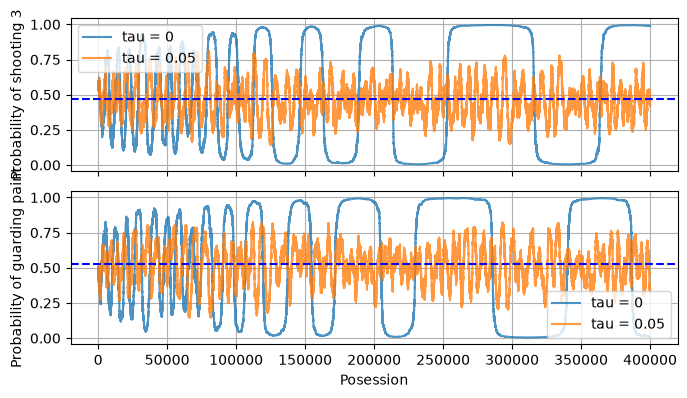

tau = 0
Last quarter average x: 0.5188921843470883
Last quarter average y: 0.4669979723435742
Early mean distance: 0.4041003418669665
Late mean distance: 0.6698151357710517
tau = 0.05
Last quarter average x: 0.4544187792225904
Last quarter average y: 0.5181807358207442
Early mean distance: 0.1916936788517007
Late mean distance: 0.15455241429885191


In [9]:
# Part (ii)
def sigmoid(theta):
    return 1 / (1 + np.exp(-theta))

def simulate(tau, seed = 42):
    rng = np.random.default_rng(seed)
    theta1, theta2 = 0.3, -0.3
    b1 = 0.0
    b2 = 0.0

    x_vals = np.zeros(N)
    y_vals = np.zeros(N)

    for t in range(N):
        x = sigmoid(theta1)
        y = sigmoid(theta2)

        # actions
        a1 = int(rng.random() < x)  # 1 = shoot 3
        a2 = int(rng.random() < y)  # 1 = guard paint

        # probability
        if a1 == 0:
            p_make = 0.40 if a2 == 1 else 0.60
            points = 2
        else:
            p_make = 0.40 if a2 == 1 else 0.25
            points = 3

        reward = points if rng.random() < p_make else 0
        r1 = reward
        r2 = -reward

        # add endropy bonus
        theta1 += eta * ((r1 - b1) * (a1 - x) - tau * theta1 * x * (1 - x))
        theta2 += eta * ((r2 - b2) * (a2 - y) - tau * theta2 * y * (1 - y))

        # baselines
        b1 += (r1 - b1) / (t + 1)
        b2 += (r2 - b2) / (t + 1)

        x_vals[t] = sigmoid(theta1)
        y_vals[t] = sigmoid(theta2)

    return x_vals, y_vals

results = {}
for tau in [0, 0.05]:
    results[tau] = simulate(tau)  

# Plots
fig, axes = plt.subplots(2, 1, figsize = (7, 4), sharex = True)
for tau, (x, y) in results.items():
    axes[0].plot(x, label = f"tau = {tau}", alpha = 0.8)
    axes[1].plot(y, label = f"tau = {tau}", alpha = 0.8)

axes[0].axhline(x_star, linestyle = "--", color = "blue")
axes[1].axhline(y_star, linestyle = "--", color = "blue")
axes[0].set_ylabel("Probability of shooting 3")
axes[1].set_ylabel("Probability of guarding paint")
axes[1].set_xlabel("Posession")

for ax in axes:
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

# Report last-quarter averange and mean distance from equilibrium early and late
for tau, (x, y) in results.items():
    distance = np.sqrt((x - x_star) ** 2 + (y - y_star) ** 2)
    print(f"tau = {tau}")
    print("Last quarter average x:", np.mean(x[3 * N // 4:]))
    print("Last quarter average y:", np.mean(y[3 * N // 4:]))
    print("Early mean distance:", np.mean(distance[:N // 4]))
    print("Late mean distance:", np.mean(distance[3 * N // 4:]))